In [1]:
# STEP 1: DEFINE INVENTORY AND LAUNCH SCENARIOS

from pathlib import Path
import pandas as pd
import numpy as np

# ------------------------------------------------------------
# PART 1: LOCATE FORECASTING INPUT
# ------------------------------------------------------------

project_root = Path.cwd()
processed_dir = project_root / "data" / "processed"

forecast_path = (
    processed_dir / "forecast_lead_time_baseline_2019.csv"
)

assert forecast_path.is_file(), (
    f"Forecast input not found: {forecast_path}"
)

forecast_df = pd.read_csv(
    forecast_path,
    parse_dates=[
        "Forecast_Origin",
        "Forecast_Week"
    ]
)

forecast_df = (
    forecast_df
    .sort_values("Lead_Time_Weeks")
    .reset_index(drop=True)
)

print("===== FORECAST INPUT VALIDATION =====")

print("Forecast records:", len(forecast_df))

print(
    "Historical origin:",
    forecast_df["Forecast_Origin"].iloc[0].date()
)

display(forecast_df)


# ------------------------------------------------------------
# PART 2: VALIDATE FOUR-WEEK DEMAND BASELINE
# ------------------------------------------------------------

assert len(forecast_df) == 4

assert forecast_df["Lead_Time_Weeks"].tolist() == [
    1, 2, 3, 4
]

assert forecast_df["Forecast_Origin"].nunique() == 1

assert (
    forecast_df["Forecast_Weekly_Units"] >= 0
).all()

assert np.allclose(
    forecast_df["Cumulative_Forecast_Units"],
    forecast_df["Forecast_Weekly_Units"].cumsum()
)

baseline_weekly_demand = (
    forecast_df["Forecast_Weekly_Units"].to_numpy(
        dtype=float
    )
)

baseline_total_demand = baseline_weekly_demand.sum()

print("\n===== HISTORICAL DEMAND BASELINE =====")

print(
    "Four-week forecast units:",
    baseline_total_demand
)


# ------------------------------------------------------------
# PART 3: DEFINE HYPOTHETICAL INVENTORY INPUTS
# ------------------------------------------------------------

starting_inventory = 1400

incoming_shipment_units = 900

scheduled_arrival_week = 3

delayed_arrival_week = 5

demand_surge_multiplier = 1.25

planning_weeks = 4

print("\n===== INVENTORY ASSUMPTIONS =====")

inventory_assumptions = pd.DataFrame([
    {
        "Parameter": "Starting inventory",
        "Value": starting_inventory,
        "Unit": "Units",
        "Source": "Hypothetical"
    },
    {
        "Parameter": "Inbound shipment",
        "Value": incoming_shipment_units,
        "Unit": "Units",
        "Source": "Hypothetical"
    },
    {
        "Parameter": "Scheduled arrival",
        "Value": scheduled_arrival_week,
        "Unit": "Planning week",
        "Source": "Hypothetical"
    },
    {
        "Parameter": "Delayed arrival",
        "Value": delayed_arrival_week,
        "Unit": "Planning week",
        "Source": "Hypothetical"
    },
    {
        "Parameter": "Demand surge",
        "Value": 25,
        "Unit": "%",
        "Source": "Hypothetical"
    }
])

display(inventory_assumptions)


# ------------------------------------------------------------
# PART 4: DEFINE THREE INVENTORY SCENARIOS
# ------------------------------------------------------------

scenario_definitions = pd.DataFrame([
    {
        "Scenario": "Baseline",
        "Demand_Multiplier": 1.00,
        "Starting_Inventory": starting_inventory,
        "Inbound_Units": incoming_shipment_units,
        "Inbound_Week": scheduled_arrival_week
    },
    {
        "Scenario": "Demand Surge",
        "Demand_Multiplier": demand_surge_multiplier,
        "Starting_Inventory": starting_inventory,
        "Inbound_Units": incoming_shipment_units,
        "Inbound_Week": scheduled_arrival_week
    },
    {
        "Scenario": "Supplier Delay",
        "Demand_Multiplier": 1.00,
        "Starting_Inventory": starting_inventory,
        "Inbound_Units": incoming_shipment_units,
        "Inbound_Week": delayed_arrival_week
    }
])

print("\n===== INVENTORY SCENARIOS =====")

display(scenario_definitions)


# ------------------------------------------------------------
# PART 5: CALCULATE DEMAND BY SCENARIO
# ------------------------------------------------------------

scenario_demand_records = []

for scenario in scenario_definitions.itertuples(index=False):

    weekly_demand = np.ceil(
        baseline_weekly_demand
        * scenario.Demand_Multiplier
    ).astype(int)

    scenario_demand_records.append({
        "Scenario": scenario.Scenario,
        "Four_Week_Demand": int(weekly_demand.sum()),
        "Starting_Inventory": scenario.Starting_Inventory,
        "Inbound_Units": scenario.Inbound_Units,
        "Inbound_Week": scenario.Inbound_Week
    })

scenario_demand_summary = pd.DataFrame(
    scenario_demand_records
)

print("\n===== SCENARIO DEMAND SUMMARY =====")

display(scenario_demand_summary)


# ------------------------------------------------------------
# PART 6: VALIDATE SCENARIO CONFIGURATION
# ------------------------------------------------------------

assert len(scenario_definitions) == 3

assert planning_weeks == len(forecast_df)

assert (
    scenario_definitions["Starting_Inventory"] >= 0
).all()

assert (
    scenario_definitions["Inbound_Units"] >= 0
).all()

assert (
    scenario_definitions["Inbound_Week"] >= 1
).all()

assert (
    scenario_definitions["Demand_Multiplier"] > 0
).all()

print("\n===== SCENARIO VALIDATION =====")

print("Three scenarios defined: PASS")
print("Historical forecast inputs loaded: PASS")
print("Nonnegative inventory and supply: PASS")
print("Valid inbound arrival weeks: PASS")

print("\n===== STEP 1 COMPLETE =====")


===== FORECAST INPUT VALIDATION =====
Forecast records: 4
Historical origin: 2019-12-29


,Forecast_Origin,Forecast_Week,Lead_Time_Weeks,Model,Forecast_Weekly_Units,Cumulative_Forecast_Units,Scenario_Type
0,2019-12-29,2020-01-05,1,Naive Forecast,515.0,515.0,Historical Illustrative Baseline
1,2019-12-29,2020-01-12,2,Naive Forecast,515.0,1030.0,Historical Illustrative Baseline
2,2019-12-29,2020-01-19,3,Naive Forecast,515.0,1545.0,Historical Illustrative Baseline
3,2019-12-29,2020-01-26,4,Naive Forecast,515.0,2060.0,Historical Illustrative Baseline



===== HISTORICAL DEMAND BASELINE =====
Four-week forecast units: 2060.0

===== INVENTORY ASSUMPTIONS =====


,Parameter,Value,Unit,Source
0,Starting inventory,1400,Units,Hypothetical
1,Inbound shipment,900,Units,Hypothetical
2,Scheduled arrival,3,Planning week,Hypothetical
3,Delayed arrival,5,Planning week,Hypothetical
4,Demand surge,25,%,Hypothetical



===== INVENTORY SCENARIOS =====


,Scenario,Demand_Multiplier,Starting_Inventory,Inbound_Units,Inbound_Week
0,Baseline,1.00,1400,900,3
1,Demand Surge,1.25,1400,900,3
2,Supplier Delay,1.00,1400,900,5



===== SCENARIO DEMAND SUMMARY =====


,Scenario,Four_Week_Demand,Starting_Inventory,Inbound_Units,Inbound_Week
0,Baseline,2060,1400,900,3
1,Demand Surge,2576,1400,900,3
2,Supplier Delay,2060,1400,900,5



===== SCENARIO VALIDATION =====
Three scenarios defined: PASS
Historical forecast inputs loaded: PASS
Nonnegative inventory and supply: PASS
Valid inbound arrival weeks: PASS

===== STEP 1 COMPLETE =====


In [2]:
# STEP 2: SIMULATE WEEKLY INVENTORY MOVEMENT

import pandas as pd
import numpy as np

# ------------------------------------------------------------
# PART 1: CREATE INVENTORY SIMULATION FUNCTION
# ------------------------------------------------------------

def simulate_inventory(scenario, forecast_data):

    inventory = int(scenario.Starting_Inventory)

    inbound_units = int(scenario.Inbound_Units)
    inbound_week = int(scenario.Inbound_Week)

    demand_multiplier = float(
        scenario.Demand_Multiplier
    )

    simulation_records = []

    # --------------------------------------------------------
    # PART 2: SIMULATE EACH PLANNING WEEK
    # --------------------------------------------------------

    for week in forecast_data.itertuples(index=False):

        week_number = int(week.Lead_Time_Weeks)

        beginning_inventory = inventory

        # Inbound inventory arrives at the beginning
        # of its scheduled week.
        if week_number == inbound_week:
            receipts = inbound_units
        else:
            receipts = 0

        available_inventory = (
            beginning_inventory + receipts
        )

        # Round demand up to whole physical units.
        weekly_demand = int(
            np.ceil(
                week.Forecast_Weekly_Units
                * demand_multiplier
            )
        )

        # Cannot fulfill more than available inventory.
        fulfilled_units = min(
            available_inventory,
            weekly_demand
        )

        # Unfulfilled demand is treated as lost sales.
        shortage_units = (
            weekly_demand - fulfilled_units
        )

        ending_inventory = (
            available_inventory - fulfilled_units
        )

        # Identify weeks with unmet demand.
        shortage_flag = int(shortage_units > 0)

        # Weekly unit fill rate.
        fill_rate_pct = (
            fulfilled_units / weekly_demand * 100
            if weekly_demand > 0
            else 100.0
        )

        simulation_records.append({
            "Scenario": scenario.Scenario,
            "Week": week_number,
            "Forecast_Week": week.Forecast_Week,
            "Beginning_Inventory": beginning_inventory,
            "Inbound_Receipts": receipts,
            "Available_Inventory": available_inventory,
            "Demand_Units": weekly_demand,
            "Fulfilled_Units": fulfilled_units,
            "Shortage_Units": shortage_units,
            "Ending_Inventory": ending_inventory,
            "Shortage_Flag": shortage_flag,
            "Weekly_Fill_Rate_Pct": fill_rate_pct
        })

        # Carry remaining inventory into the next week.
        inventory = ending_inventory

    return pd.DataFrame(simulation_records)


# ------------------------------------------------------------
# PART 3: RUN ALL THREE SCENARIOS
# ------------------------------------------------------------

scenario_results = []

for scenario in scenario_definitions.itertuples(index=False):

    result = simulate_inventory(
        scenario,
        forecast_df
    )

    scenario_results.append(result)

inventory_simulation = pd.concat(
    scenario_results,
    ignore_index=True
)

print("===== WEEKLY INVENTORY SIMULATION =====")

display(inventory_simulation.round(2))


# ------------------------------------------------------------
# PART 4: CALCULATE SCENARIO PERFORMANCE
# ------------------------------------------------------------

scenario_performance = (
    inventory_simulation
    .groupby("Scenario", sort=False)
    .agg(
        Total_Demand=("Demand_Units", "sum"),
        Total_Fulfilled=("Fulfilled_Units", "sum"),
        Total_Shortage=("Shortage_Units", "sum"),
        Receipts_In_Horizon=("Inbound_Receipts", "sum"),
        Shortage_Weeks=("Shortage_Flag", "sum"),
        Ending_Inventory=("Ending_Inventory", "last")
    )
    .reset_index()
)

scenario_performance["Fill_Rate_Pct"] = (
    scenario_performance["Total_Fulfilled"]
    / scenario_performance["Total_Demand"]
    * 100
)

print("\n===== INVENTORY SCENARIO PERFORMANCE =====")

display(scenario_performance.round(2))


# ------------------------------------------------------------
# PART 5: VALIDATE INVENTORY FLOW
# ------------------------------------------------------------

# Three scenarios x four weeks = twelve records.
assert len(inventory_simulation) == 12

# Inventory cannot become negative.
assert (
    inventory_simulation["Ending_Inventory"] >= 0
).all()

# Fulfilled demand cannot exceed actual demand.
assert (
    inventory_simulation["Fulfilled_Units"]
    <= inventory_simulation["Demand_Units"]
).all()

# Demand must equal fulfilled units plus shortages.
assert (
    inventory_simulation["Demand_Units"]
    ==
    inventory_simulation["Fulfilled_Units"]
    + inventory_simulation["Shortage_Units"]
).all()

# Inventory must reconcile within each week.
assert (
    inventory_simulation["Beginning_Inventory"]
    + inventory_simulation["Inbound_Receipts"]
    ==
    inventory_simulation["Fulfilled_Units"]
    + inventory_simulation["Ending_Inventory"]
).all()

# Each next week begins with the previous ending inventory.
for scenario_name, group in inventory_simulation.groupby("Scenario"):

    group = group.sort_values("Week")

    assert np.array_equal(
        group["Beginning_Inventory"].iloc[1:].to_numpy(),
        group["Ending_Inventory"].iloc[:-1].to_numpy()
    )

# Each scenario's total demand must match Step 1.
demand_check = scenario_performance.merge(
    scenario_demand_summary[
        ["Scenario", "Four_Week_Demand"]
    ],
    on="Scenario",
    validate="one_to_one"
)

assert (
    demand_check["Total_Demand"]
    == demand_check["Four_Week_Demand"]
).all()

print("\n===== INVENTORY SIMULATION VALIDATION =====")

print("12 weekly simulation records: PASS")
print("Nonnegative ending inventory: PASS")
print("Demand fulfillment reconciliation: PASS")
print("Weekly inventory flow reconciliation: PASS")
print("Beginning/ending inventory continuity: PASS")
print("Scenario demand totals: PASS")

print("\n===== STEP 2 COMPLETE =====")


===== WEEKLY INVENTORY SIMULATION =====


/var/folders/9c/495l1cs96zj_67bnbpkg5lm80000gn/T/ipykernel_25559/3895832.py:120: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(inventory_simulation.round(2))


,Scenario,Week,Forecast_Week,Beginning_Inventory,Inbound_Receipts,Available_Inventory,Demand_Units,Fulfilled_Units,Shortage_Units,Ending_Inventory,Shortage_Flag,Weekly_Fill_Rate_Pct
0,Baseline,1,2020-01-05,1400,0,1400,515,515,0,885,0,100.00
1,Baseline,2,2020-01-12,885,0,885,515,515,0,370,0,100.00
2,Baseline,3,2020-01-19,370,900,1270,515,515,0,755,0,100.00
3,Baseline,4,2020-01-26,755,0,755,515,515,0,240,0,100.00
4,Demand Surge,1,2020-01-05,1400,0,1400,644,644,0,756,0,100.00
5,Demand Surge,2,2020-01-12,756,0,756,644,644,0,112,0,100.00
6,Demand Surge,3,2020-01-19,112,900,1012,644,644,0,368,0,100.00
7,Demand Surge,4,2020-01-26,368,0,368,644,368,276,0,1,57.14
8,Supplier Delay,1,2020-01-05,1400,0,1400,515,515,0,885,0,100.00
9,Supplier Delay,2,2020-01-12,885,0,885,515,515,0,370,0,100.00



===== INVENTORY SCENARIO PERFORMANCE =====


,Scenario,Total_Demand,Total_Fulfilled,Total_Shortage,Receipts_In_Horizon,Shortage_Weeks,Ending_Inventory,Fill_Rate_Pct
0,Baseline,2060,2060,0,900,0,240,100.00
1,Demand Surge,2576,2300,276,900,1,0,89.29
2,Supplier Delay,2060,1400,660,0,2,0,67.96



===== INVENTORY SIMULATION VALIDATION =====
12 weekly simulation records: PASS
Nonnegative ending inventory: PASS
Demand fulfillment reconciliation: PASS
Weekly inventory flow reconciliation: PASS
Beginning/ending inventory continuity: PASS
Scenario demand totals: PASS

===== STEP 2 COMPLETE =====


===== WEEKLY INVENTORY RISK =====


,Scenario,Week,Demand_Units,Shortage_Units,Cumulative_Shortage,Ending_Inventory,Cumulative_Fill_Rate_Pct
0,Baseline,1,515,0,0,885,100.00
1,Baseline,2,515,0,0,370,100.00
2,Baseline,3,515,0,0,755,100.00
3,Baseline,4,515,0,0,240,100.00
4,Demand Surge,1,644,0,0,756,100.00
5,Demand Surge,2,644,0,0,112,100.00
6,Demand Surge,3,644,0,0,368,100.00
7,Demand Surge,4,644,276,276,0,89.29
8,Supplier Delay,1,515,0,0,885,100.00
9,Supplier Delay,2,515,0,0,370,100.00



===== INVENTORY SHORTAGE RISK SUMMARY =====


,Scenario,First_Shortage_Week,First_Shortage_Date,Shortage_Weeks,Peak_Weekly_Shortage,Total_Unfulfilled_Units,Unfulfilled_Demand_Pct,Overall_Fill_Rate_Pct,Fill_Rate_Gap_vs_Baseline_pp,Additional_Units_Needed
0,Baseline,NaN,N/A,0,0,0,0.00,100.00,0.00,0
1,Demand Surge,4.0,2020-01-26,1,276,276,10.71,89.29,10.71,276
2,Supplier Delay,3.0,2020-01-19,2,515,660,32.04,67.96,32.04,660


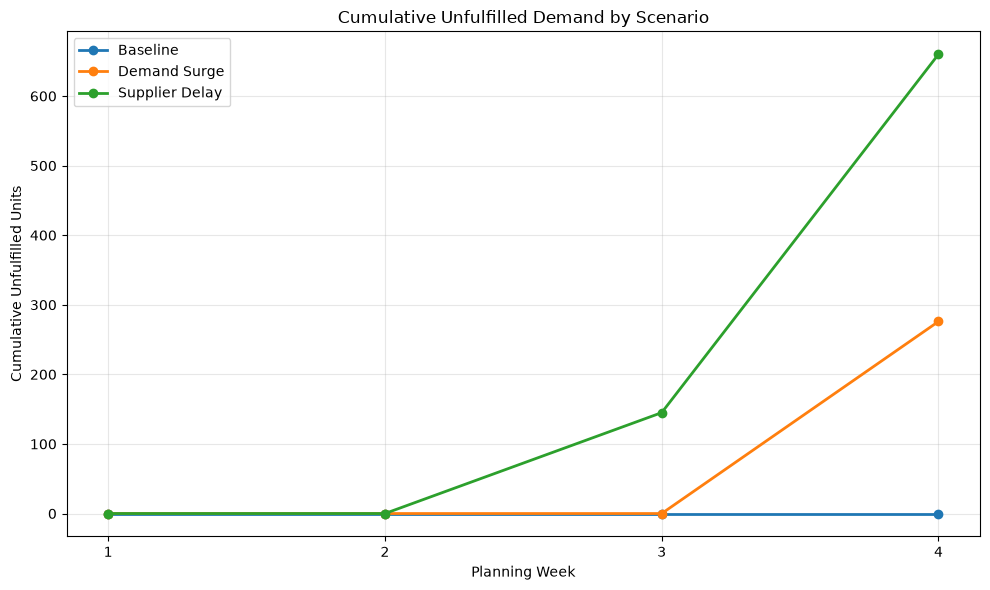


===== INVENTORY RISK VALIDATION =====
Three scenarios evaluated: PASS
Cumulative shortage reconciliation: PASS
Scenario service-level reconciliation: PASS
Expected shortage outcomes: PASS

===== STEP 3 COMPLETE =====


In [3]:
# STEP 3: ANALYZE INVENTORY SHORTAGES AND SERVICE RISK

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# PART 1: BUILD CUMULATIVE INVENTORY RISK METRICS
# ------------------------------------------------------------

weekly_risk = (
    inventory_simulation
    .sort_values(["Scenario", "Week"])
    .copy()
    .reset_index(drop=True)
)

weekly_risk["Cumulative_Demand"] = (
    weekly_risk.groupby("Scenario")["Demand_Units"]
    .cumsum()
)

weekly_risk["Cumulative_Fulfilled"] = (
    weekly_risk.groupby("Scenario")["Fulfilled_Units"]
    .cumsum()
)

weekly_risk["Cumulative_Shortage"] = (
    weekly_risk.groupby("Scenario")["Shortage_Units"]
    .cumsum()
)

weekly_risk["Cumulative_Fill_Rate_Pct"] = (
    weekly_risk["Cumulative_Fulfilled"]
    / weekly_risk["Cumulative_Demand"]
    * 100
)

print("===== WEEKLY INVENTORY RISK =====")

display(
    weekly_risk[
        [
            "Scenario",
            "Week",
            "Demand_Units",
            "Shortage_Units",
            "Cumulative_Shortage",
            "Ending_Inventory",
            "Cumulative_Fill_Rate_Pct"
        ]
    ].round(2)
)


# ------------------------------------------------------------
# PART 2: IDENTIFY FIRST SHORTAGE AND PEAK EXPOSURE
# ------------------------------------------------------------

risk_records = []

baseline_fill_rate = float(
    scenario_performance.loc[
        scenario_performance["Scenario"] == "Baseline",
        "Fill_Rate_Pct"
    ].iloc[0]
)

for scenario_name in scenario_definitions["Scenario"]:

    scenario_weeks = weekly_risk[
        weekly_risk["Scenario"] == scenario_name
    ].sort_values("Week")

    shortage_weeks = scenario_weeks[
        scenario_weeks["Shortage_Units"] > 0
    ]

    if shortage_weeks.empty:
        first_shortage_week = None
        first_shortage_date = "N/A"
    else:
        first_row = shortage_weeks.iloc[0]

        first_shortage_week = int(
            first_row["Week"]
        )

        first_shortage_date = str(
            pd.to_datetime(
                first_row["Forecast_Week"]
            ).date()
        )

    total_demand = int(
        scenario_weeks["Demand_Units"].sum()
    )

    total_shortage = int(
        scenario_weeks["Shortage_Units"].sum()
    )

    total_fulfilled = int(
        scenario_weeks["Fulfilled_Units"].sum()
    )

    overall_fill_rate = (
        total_fulfilled / total_demand * 100
    )

    risk_records.append({
        "Scenario": scenario_name,
        "First_Shortage_Week": first_shortage_week,
        "First_Shortage_Date": first_shortage_date,
        "Shortage_Weeks": len(shortage_weeks),
        "Peak_Weekly_Shortage": int(
            scenario_weeks["Shortage_Units"].max()
        ),
        "Total_Unfulfilled_Units": total_shortage,
        "Unfulfilled_Demand_Pct": (
            total_shortage / total_demand * 100
        ),
        "Overall_Fill_Rate_Pct": overall_fill_rate,
        "Fill_Rate_Gap_vs_Baseline_pp": (
            baseline_fill_rate - overall_fill_rate
        ),
        "Additional_Units_Needed": total_shortage
    })


# ------------------------------------------------------------
# PART 3: CREATE OPERATIONAL RISK SUMMARY
# ------------------------------------------------------------

inventory_risk_summary = pd.DataFrame(
    risk_records
)

print("\n===== INVENTORY SHORTAGE RISK SUMMARY =====")

display(
    inventory_risk_summary.round(2)
)


# ------------------------------------------------------------
# PART 4: VISUALIZE CUMULATIVE SHORTAGE EXPOSURE
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 6))

for scenario_name, group in weekly_risk.groupby(
    "Scenario",
    sort=False
):

    ax.plot(
        group["Week"],
        group["Cumulative_Shortage"],
        marker="o",
        linewidth=2,
        label=scenario_name
    )

ax.set_title(
    "Cumulative Unfulfilled Demand by Scenario"
)

ax.set_xlabel("Planning Week")
ax.set_ylabel("Cumulative Unfulfilled Units")

ax.set_xticks([1, 2, 3, 4])
ax.grid(alpha=0.3)
ax.legend()

fig.tight_layout()
plt.show()


# ------------------------------------------------------------
# PART 5: VALIDATE RISK METRICS
# ------------------------------------------------------------

assert len(inventory_risk_summary) == 3

assert len(weekly_risk) == 12

# Cumulative shortages must never decrease.
for _, group in weekly_risk.groupby("Scenario"):

    assert (
        group["Cumulative_Shortage"]
        .is_monotonic_increasing
    )

# Scenario totals must reconcile with Step 2.
reconciliation = inventory_risk_summary.merge(
    scenario_performance[
        ["Scenario", "Total_Shortage", "Fill_Rate_Pct"]
    ],
    on="Scenario",
    validate="one_to_one"
)

assert (
    reconciliation["Total_Unfulfilled_Units"]
    == reconciliation["Total_Shortage"]
).all()

assert np.allclose(
    reconciliation["Overall_Fill_Rate_Pct"],
    reconciliation["Fill_Rate_Pct"]
)

# Verify expected scenario shortage outcomes.
expected_shortages = {
    "Baseline": 0,
    "Demand Surge": 276,
    "Supplier Delay": 660
}

for scenario_name, expected_units in (
    expected_shortages.items()
):

    actual_units = int(
        inventory_risk_summary.loc[
            inventory_risk_summary["Scenario"]
            == scenario_name,
            "Total_Unfulfilled_Units"
        ].iloc[0]
    )

    assert actual_units == expected_units


print("\n===== INVENTORY RISK VALIDATION =====")

print("Three scenarios evaluated: PASS")
print("Cumulative shortage reconciliation: PASS")
print("Scenario service-level reconciliation: PASS")
print("Expected shortage outcomes: PASS")

print("\n===== STEP 3 COMPLETE =====")


In [4]:

# STEP 4: EVALUATE INVENTORY REPLENISHMENT ALTERNATIVES

import pandas as pd
import numpy as np

# ------------------------------------------------------------
# PART 1: DEFINE REPLENISHMENT ACTIONS
# ------------------------------------------------------------

# An arrival week of 0 means no additional delivery.
# Reschedule_Week = 0 means retain original shipment timing.

intervention_definitions = pd.DataFrame([
    {
        "Scenario": "Demand Surge",
        "Action": "No Intervention",
        "Extra_Units": 0,
        "Extra_Arrival_Week": 0,
        "Reschedule_Week": 0
    },
    {
        "Scenario": "Demand Surge",
        "Action": "Add 276 Units - Week 4",
        "Extra_Units": 276,
        "Extra_Arrival_Week": 4,
        "Reschedule_Week": 0
    },
    {
        "Scenario": "Demand Surge",
        "Action": "Add 276 Units - Week 5",
        "Extra_Units": 276,
        "Extra_Arrival_Week": 5,
        "Reschedule_Week": 0
    },
    {
        "Scenario": "Supplier Delay",
        "Action": "No Intervention",
        "Extra_Units": 0,
        "Extra_Arrival_Week": 0,
        "Reschedule_Week": 0
    },
    {
        "Scenario": "Supplier Delay",
        "Action": "Bridge 660 Units - Week 3",
        "Extra_Units": 660,
        "Extra_Arrival_Week": 3,
        "Reschedule_Week": 0
    },
    {
        "Scenario": "Supplier Delay",
        "Action": "Bridge 660 Units - Week 4",
        "Extra_Units": 660,
        "Extra_Arrival_Week": 4,
        "Reschedule_Week": 0
    },
    {
        "Scenario": "Supplier Delay",
        "Action": "Expedite Original 900 - Week 3",
        "Extra_Units": 0,
        "Extra_Arrival_Week": 0,
        "Reschedule_Week": 3
    }
])

print("===== REPLENISHMENT ACTIONS =====")

display(intervention_definitions)


# ------------------------------------------------------------
# PART 2: BUILD SUPPLY INTERVENTION SIMULATOR
# ------------------------------------------------------------

scenario_lookup = scenario_definitions.set_index(
    "Scenario"
)

def simulate_intervention(action):

    scenario = scenario_lookup.loc[action.Scenario]

    inventory = int(scenario["Starting_Inventory"])

    original_units = int(scenario["Inbound_Units"])
    original_week = int(scenario["Inbound_Week"])

    # A rescheduled shipment replaces original timing.
    if action.Reschedule_Week > 0:
        original_week = int(action.Reschedule_Week)

    extra_units = int(action.Extra_Units)
    extra_week = int(action.Extra_Arrival_Week)

    multiplier = float(scenario["Demand_Multiplier"])

    records = []

    for week in forecast_df.itertuples(index=False):

        week_number = int(week.Lead_Time_Weeks)

        beginning = inventory

        original_receipts = (
            original_units
            if week_number == original_week
            else 0
        )

        extra_receipts = (
            extra_units
            if week_number == extra_week
            else 0
        )

        total_receipts = (
            original_receipts + extra_receipts
        )

        available = beginning + total_receipts

        demand = int(
            np.ceil(
                week.Forecast_Weekly_Units * multiplier
            )
        )

        fulfilled = min(available, demand)

        shortage = demand - fulfilled

        ending = available - fulfilled

        records.append({
            "Scenario": action.Scenario,
            "Action": action.Action,
            "Week": week_number,
            "Demand": demand,
            "Original_Receipts": original_receipts,
            "Extra_Receipts": extra_receipts,
            "Beginning_Inventory": beginning,
            "Fulfilled": fulfilled,
            "Shortage": shortage,
            "Ending_Inventory": ending
        })

        inventory = ending

    return pd.DataFrame(records)


# ------------------------------------------------------------
# PART 3: SIMULATE ALL SEVEN ACTIONS
# ------------------------------------------------------------

simulation_outputs = []

for action in intervention_definitions.itertuples(index=False):

    result = simulate_intervention(action)

    simulation_outputs.append(result)

intervention_weekly = pd.concat(
    simulation_outputs,
    ignore_index=True
)

print("\n===== WEEKLY INTERVENTION SIMULATION =====")

print("Weekly simulation records:", len(intervention_weekly))

display(
    intervention_weekly[
        [
            "Scenario",
            "Action",
            "Week",
            "Demand",
            "Original_Receipts",
            "Extra_Receipts",
            "Shortage",
            "Ending_Inventory"
        ]
    ]
)


# ------------------------------------------------------------
# PART 4: CALCULATE INTERVENTION PERFORMANCE
# ------------------------------------------------------------

intervention_summary = (
    intervention_weekly
    .groupby(["Scenario", "Action"], sort=False)
    .agg(
        Total_Demand=("Demand", "sum"),
        Total_Fulfilled=("Fulfilled", "sum"),
        Total_Shortage=("Shortage", "sum"),
        Original_Receipts=("Original_Receipts", "sum"),
        Extra_Receipts=("Extra_Receipts", "sum"),
        Ending_Inventory=("Ending_Inventory", "last")
    )
    .reset_index()
)

intervention_summary["Fill_Rate_Pct"] = (
    intervention_summary["Total_Fulfilled"]
    / intervention_summary["Total_Demand"]
    * 100
)

# Compare every option with its original no-action scenario.
base_shortages = (
    scenario_performance
    .set_index("Scenario")["Total_Shortage"]
)

base_fill_rates = (
    scenario_performance
    .set_index("Scenario")["Fill_Rate_Pct"]
)

intervention_summary["Shortage_Reduction"] = (
    intervention_summary["Scenario"].map(base_shortages)
    - intervention_summary["Total_Shortage"]
)

intervention_summary["Fill_Rate_Improvement_pp"] = (
    intervention_summary["Fill_Rate_Pct"]
    - intervention_summary["Scenario"].map(base_fill_rates)
)

print("\n===== REPLENISHMENT PERFORMANCE =====")

display(
    intervention_summary[
        [
            "Scenario",
            "Action",
            "Total_Shortage",
            "Fill_Rate_Pct",
            "Shortage_Reduction",
            "Fill_Rate_Improvement_pp",
            "Extra_Receipts",
            "Ending_Inventory"
        ]
    ].round(2)
)


# ------------------------------------------------------------
# PART 5: VALIDATE REPLENISHMENT RESULTS
# ------------------------------------------------------------

assert len(intervention_definitions) == 7
assert len(intervention_weekly) == 28
assert len(intervention_summary) == 7

assert (
    intervention_weekly["Ending_Inventory"] >= 0
).all()

assert (
    intervention_weekly["Demand"]
    ==
    intervention_weekly["Fulfilled"]
    + intervention_weekly["Shortage"]
).all()

assert (
    intervention_weekly["Beginning_Inventory"]
    + intervention_weekly["Original_Receipts"]
    + intervention_weekly["Extra_Receipts"]
    ==
    intervention_weekly["Fulfilled"]
    + intervention_weekly["Ending_Inventory"]
).all()

# Verify the model reproduces our earlier baselines.
expected_shortages = {
    ("Demand Surge", "No Intervention"): 276,
    ("Demand Surge", "Add 276 Units - Week 4"): 0,
    ("Demand Surge", "Add 276 Units - Week 5"): 276,
    ("Supplier Delay", "No Intervention"): 660,
    ("Supplier Delay", "Bridge 660 Units - Week 3"): 0,
    ("Supplier Delay", "Bridge 660 Units - Week 4"): 145,
    ("Supplier Delay", "Expedite Original 900 - Week 3"): 0
}

for (scenario_name, action_name), expected in (
    expected_shortages.items()
):

    actual = intervention_summary.loc[
        (
            intervention_summary["Scenario"] == scenario_name
        )
        &
        (
            intervention_summary["Action"] == action_name
        ),
        "Total_Shortage"
    ].iloc[0]

    assert actual == expected, (
        f"Unexpected shortage: {scenario_name}, {action_name}"
    )

print("\n===== INTERVENTION VALIDATION =====")

print("Seven replenishment alternatives: PASS")
print("28 simulated planning weeks: PASS")
print("Inventory and demand reconciliations: PASS")
print("Original shipment not double counted: PASS")
print("Expected shortage outcomes: PASS")

print("\n===== STEP 4 COMPLETE =====")


===== REPLENISHMENT ACTIONS =====


,Scenario,Action,Extra_Units,Extra_Arrival_Week,Reschedule_Week
0,Demand Surge,No Intervention,0,0,0
1,Demand Surge,Add 276 Units - Week 4,276,4,0
2,Demand Surge,Add 276 Units - Week 5,276,5,0
3,Supplier Delay,No Intervention,0,0,0
4,Supplier Delay,Bridge 660 Units - Week 3,660,3,0
5,Supplier Delay,Bridge 660 Units - Week 4,660,4,0
6,Supplier Delay,Expedite Original 900 - Week 3,0,0,3



===== WEEKLY INTERVENTION SIMULATION =====
Weekly simulation records: 28


,Scenario,Action,Week,Demand,Original_Receipts,Extra_Receipts,Shortage,Ending_Inventory
0,Demand Surge,No Intervention,1,644,0,0,0,756
1,Demand Surge,No Intervention,2,644,0,0,0,112
2,Demand Surge,No Intervention,3,644,900,0,0,368
3,Demand Surge,No Intervention,4,644,0,0,276,0
4,Demand Surge,Add 276 Units - Week 4,1,644,0,0,0,756
5,Demand Surge,Add 276 Units - Week 4,2,644,0,0,0,112
6,Demand Surge,Add 276 Units - Week 4,3,644,900,0,0,368
7,Demand Surge,Add 276 Units - Week 4,4,644,0,276,0,0
8,Demand Surge,Add 276 Units - Week 5,1,644,0,0,0,756
9,Demand Surge,Add 276 Units - Week 5,2,644,0,0,0,112



===== REPLENISHMENT PERFORMANCE =====


,Scenario,Action,Total_Shortage,Fill_Rate_Pct,Shortage_Reduction,Fill_Rate_Improvement_pp,Extra_Receipts,Ending_Inventory
0,Demand Surge,No Intervention,276,89.29,0,0.00,0,0
1,Demand Surge,Add 276 Units - Week 4,0,100.00,276,10.71,276,0
2,Demand Surge,Add 276 Units - Week 5,276,89.29,0,0.00,0,0
3,Supplier Delay,No Intervention,660,67.96,0,0.00,0,0
4,Supplier Delay,Bridge 660 Units - Week 3,0,100.00,660,32.04,660,0
5,Supplier Delay,Bridge 660 Units - Week 4,145,92.96,515,25.00,660,145
6,Supplier Delay,Expedite Original 900 - Week 3,0,100.00,660,32.04,0,240



===== INTERVENTION VALIDATION =====
Seven replenishment alternatives: PASS
28 simulated planning weeks: PASS
Inventory and demand reconciliations: PASS
Original shipment not double counted: PASS
Expected shortage outcomes: PASS

===== STEP 4 COMPLETE =====


In [5]:
# STEP 5: LAUNCH READINESS AND REPLENISHMENT DECISIONS

import pandas as pd
import numpy as np

# ------------------------------------------------------------
# PART 1: DEFINE HYPOTHETICAL DECISION CRITERIA
# ------------------------------------------------------------

launch_fill_target_pct = 98.0
watch_fill_threshold_pct = 90.0

shortage_penalty_per_unit = 75.0
emergency_premium_per_unit = 12.0
emergency_delivery_fee = 500.0
original_expediting_fee = 2500.0

print("===== HYPOTHETICAL DECISION ASSUMPTIONS =====")

print("Launch fill-rate target:", launch_fill_target_pct)
print("Watch threshold:", watch_fill_threshold_pct)
print("Shortage penalty per unit: $", shortage_penalty_per_unit)
print("Emergency premium per unit: $", emergency_premium_per_unit)
print("Emergency delivery fee: $", emergency_delivery_fee)
print("Original shipment expedite fee: $", original_expediting_fee)


# ------------------------------------------------------------
# PART 2: CALCULATE SHORTAGE TIMING
# ------------------------------------------------------------

shortage_details = (
    intervention_weekly
    .assign(
        Is_Shortage=lambda df: (
            df["Shortage"] > 0
        ).astype(int)
    )
    .groupby(
        ["Scenario", "Action"],
        as_index=False
    )
    .agg(
        Shortage_Weeks=("Is_Shortage", "sum"),
        Peak_Weekly_Shortage=("Shortage", "max")
    )
)

first_shortages = (
    intervention_weekly[
        intervention_weekly["Shortage"] > 0
    ]
    .groupby(
        ["Scenario", "Action"],
        as_index=False
    )["Week"]
    .min()
    .rename(
        columns={
            "Week": "First_Shortage_Week"
        }
    )
)


# ------------------------------------------------------------
# PART 3: BUILD LAUNCH READINESS TABLE
# ------------------------------------------------------------

launch_readiness = (
    intervention_summary
    .merge(
        intervention_definitions,
        on=["Scenario", "Action"],
        validate="one_to_one"
    )
    .merge(
        shortage_details,
        on=["Scenario", "Action"],
        validate="one_to_one"
    )
    .merge(
        first_shortages,
        on=["Scenario", "Action"],
        how="left",
        validate="one_to_one"
    )
    .merge(
        scenario_definitions[
            ["Scenario", "Inbound_Units", "Inbound_Week"]
        ],
        on="Scenario",
        validate="many_to_one"
    )
)


# ------------------------------------------------------------
# PART 4: CALCULATE SERVICE PERFORMANCE
# ------------------------------------------------------------

launch_readiness["Weeks_Without_Shortage"] = (
    planning_weeks
    - launch_readiness["Shortage_Weeks"]
)

launch_readiness["Unfulfilled_Demand_Pct"] = (
    launch_readiness["Total_Shortage"]
    / launch_readiness["Total_Demand"]
    * 100
)

# Illustrative readiness policy:
# READY: target met and zero shortage weeks
# WATCH: some shortage, but at least 90% fulfillment
# AT RISK: below the watch threshold

ready_condition = (
    (launch_readiness["Fill_Rate_Pct"]
     >= launch_fill_target_pct)
    &
    (launch_readiness["Shortage_Weeks"] == 0)
)

watch_condition = (
    launch_readiness["Fill_Rate_Pct"]
    >= watch_fill_threshold_pct
)

launch_readiness["Readiness_Status"] = np.select(
    [ready_condition, watch_condition],
    ["READY", "WATCH"],
    default="AT RISK"
)


# ------------------------------------------------------------
# PART 5: TRACK SUPPLY ARRIVING AFTER THE HORIZON
# ------------------------------------------------------------

# Rescheduling moves the original shipment.
# It does not create another original shipment.

launch_readiness["Effective_Original_Arrival_Week"] = (
    np.where(
        launch_readiness["Reschedule_Week"] > 0,
        launch_readiness["Reschedule_Week"],
        launch_readiness["Inbound_Week"]
    )
)

launch_readiness["Original_Units_After_Horizon"] = (
    np.where(
        launch_readiness["Effective_Original_Arrival_Week"]
        > planning_weeks,
        launch_readiness["Inbound_Units"],
        0
    )
)

launch_readiness["Extra_Units_After_Horizon"] = (
    np.where(
        (launch_readiness["Extra_Units"] > 0)
        &
        (launch_readiness["Extra_Arrival_Week"]
         > planning_weeks),
        launch_readiness["Extra_Units"],
        0
    )
)

launch_readiness["Total_Outstanding_Units"] = (
    launch_readiness["Original_Units_After_Horizon"]
    + launch_readiness["Extra_Units_After_Horizon"]
)


# ------------------------------------------------------------
# PART 6: CALCULATE ILLUSTRATIVE ECONOMIC EXPOSURE
# ------------------------------------------------------------

# These values are assumed for scenario comparison.
# They exclude full purchase costs, holding costs,
# and post-horizon operating consequences.

launch_readiness["Shortage_Exposure_USD"] = (
    launch_readiness["Total_Shortage"]
    * shortage_penalty_per_unit
)

launch_readiness["Emergency_Premium_USD"] = (
    launch_readiness["Extra_Receipts"]
    * emergency_premium_per_unit
)

launch_readiness["Emergency_Delivery_Fee_USD"] = (
    np.where(
        launch_readiness["Extra_Receipts"] > 0,
        emergency_delivery_fee,
        0.0
    )
)

launch_readiness["Original_Expedite_Fee_USD"] = (
    np.where(
        launch_readiness["Reschedule_Week"] > 0,
        original_expediting_fee,
        0.0
    )
)

launch_readiness["Illustrative_Exposure_USD"] = (
    launch_readiness["Shortage_Exposure_USD"]
    + launch_readiness["Emergency_Premium_USD"]
    + launch_readiness["Emergency_Delivery_Fee_USD"]
    + launch_readiness["Original_Expedite_Fee_USD"]
)


# ------------------------------------------------------------
# PART 7: COMPARE WITH NO-INTERVENTION BASELINES
# ------------------------------------------------------------

no_action_exposure = (
    launch_readiness[
        launch_readiness["Action"] == "No Intervention"
    ]
    .set_index("Scenario")[
        "Illustrative_Exposure_USD"
    ]
)

launch_readiness["Exposure_Reduction_vs_No_Action_USD"] = (
    launch_readiness["Scenario"].map(
        no_action_exposure
    )
    - launch_readiness["Illustrative_Exposure_USD"]
)


# ------------------------------------------------------------
# PART 8: DISPLAY LAUNCH READINESS
# ------------------------------------------------------------

print("\n===== LAUNCH READINESS SCORECARD =====")

display(
    launch_readiness[
        [
            "Scenario",
            "Action",
            "Total_Shortage",
            "Shortage_Weeks",
            "First_Shortage_Week",
            "Fill_Rate_Pct",
            "Readiness_Status"
        ]
    ].round(2)
)


# ------------------------------------------------------------
# PART 9: DISPLAY FINANCIAL AND INVENTORY TRADEOFFS
# ------------------------------------------------------------

print("\n===== ILLUSTRATIVE DECISION TRADEOFFS =====")

display(
    launch_readiness[
        [
            "Scenario",
            "Action",
            "Illustrative_Exposure_USD",
            "Exposure_Reduction_vs_No_Action_USD",
            "Extra_Units",
            "Total_Outstanding_Units",
            "Ending_Inventory"
        ]
    ].round(2)
)


# ------------------------------------------------------------
# PART 10: IDENTIFY CANDIDATE READY ACTIONS
# ------------------------------------------------------------

ready_actions = (
    launch_readiness[
        launch_readiness["Readiness_Status"] == "READY"
    ]
    .sort_values(
        ["Scenario", "Illustrative_Exposure_USD"]
    )
)

candidate_actions = (
    ready_actions
    .groupby("Scenario", as_index=False)
    .first()
)

print("\n===== LOWEST MODELED EXPOSURE AMONG READY ACTIONS =====")

display(
    candidate_actions[
        [
            "Scenario",
            "Action",
            "Fill_Rate_Pct",
            "Illustrative_Exposure_USD",
            "Total_Outstanding_Units"
        ]
    ].round(2)
)


# ------------------------------------------------------------
# PART 11: VALIDATE DECISION MODEL
# ------------------------------------------------------------

assert len(launch_readiness) == 7

assert (
    launch_readiness["Total_Demand"]
    ==
    launch_readiness["Total_Fulfilled"]
    + launch_readiness["Total_Shortage"]
).all()

assert (
    launch_readiness["Illustrative_Exposure_USD"]
    >= 0
).all()

assert (
    launch_readiness["Total_Outstanding_Units"]
    >= 0
).all()

assert len(ready_actions) == 3

assert (
    ready_actions["Total_Shortage"] == 0
).all()

assert len(candidate_actions) == 2

print("\n===== LAUNCH READINESS VALIDATION =====")

print("Seven interventions evaluated: PASS")
print("Service-level reconciliation: PASS")
print("Nonnegative illustrative exposure: PASS")
print("Future supply obligations tracked: PASS")
print("Three shortage-free interventions: PASS")
print("Two candidate scenario decisions: PASS")

print("\n===== STEP 5 COMPLETE =====")


===== HYPOTHETICAL DECISION ASSUMPTIONS =====
Launch fill-rate target: 98.0
Watch threshold: 90.0
Shortage penalty per unit: $ 75.0
Emergency premium per unit: $ 12.0
Emergency delivery fee: $ 500.0
Original shipment expedite fee: $ 2500.0

===== LAUNCH READINESS SCORECARD =====


,Scenario,Action,Total_Shortage,Shortage_Weeks,First_Shortage_Week,Fill_Rate_Pct,Readiness_Status
0,Demand Surge,No Intervention,276,1,4.0,89.29,AT RISK
1,Demand Surge,Add 276 Units - Week 4,0,0,NaN,100.00,READY
2,Demand Surge,Add 276 Units - Week 5,276,1,4.0,89.29,AT RISK
3,Supplier Delay,No Intervention,660,2,3.0,67.96,AT RISK
4,Supplier Delay,Bridge 660 Units - Week 3,0,0,NaN,100.00,READY
5,Supplier Delay,Bridge 660 Units - Week 4,145,1,3.0,92.96,WATCH
6,Supplier Delay,Expedite Original 900 - Week 3,0,0,NaN,100.00,READY



===== ILLUSTRATIVE DECISION TRADEOFFS =====


,Scenario,Action,Illustrative_Exposure_USD,Exposure_Reduction_vs_No_Action_USD,Extra_Units,Total_Outstanding_Units,Ending_Inventory
0,Demand Surge,No Intervention,20700.0,0.0,0,0,0
1,Demand Surge,Add 276 Units - Week 4,3812.0,16888.0,276,0,0
2,Demand Surge,Add 276 Units - Week 5,20700.0,0.0,276,276,0
3,Supplier Delay,No Intervention,49500.0,0.0,0,900,0
4,Supplier Delay,Bridge 660 Units - Week 3,8420.0,41080.0,660,900,0
5,Supplier Delay,Bridge 660 Units - Week 4,19295.0,30205.0,660,900,145
6,Supplier Delay,Expedite Original 900 - Week 3,2500.0,47000.0,0,0,240



===== LOWEST MODELED EXPOSURE AMONG READY ACTIONS =====


,Scenario,Action,Fill_Rate_Pct,Illustrative_Exposure_USD,Total_Outstanding_Units
0,Demand Surge,Add 276 Units - Week 4,100.0,3812.0,0
1,Supplier Delay,Expedite Original 900 - Week 3,100.0,2500.0,0



===== LAUNCH READINESS VALIDATION =====
Seven interventions evaluated: PASS
Service-level reconciliation: PASS
Nonnegative illustrative exposure: PASS
Future supply obligations tracked: PASS
Three shortage-free interventions: PASS
Two candidate scenario decisions: PASS

===== STEP 5 COMPLETE =====


===== OUTPUT DIRECTORIES =====
Data: /Users/sidkulkarni/Desktop/supply-chain-portfolio/hardware-demand-sensing-planner/data/processed
Figures: /Users/sidkulkarni/Desktop/supply-chain-portfolio/hardware-demand-sensing-planner/reports/figures


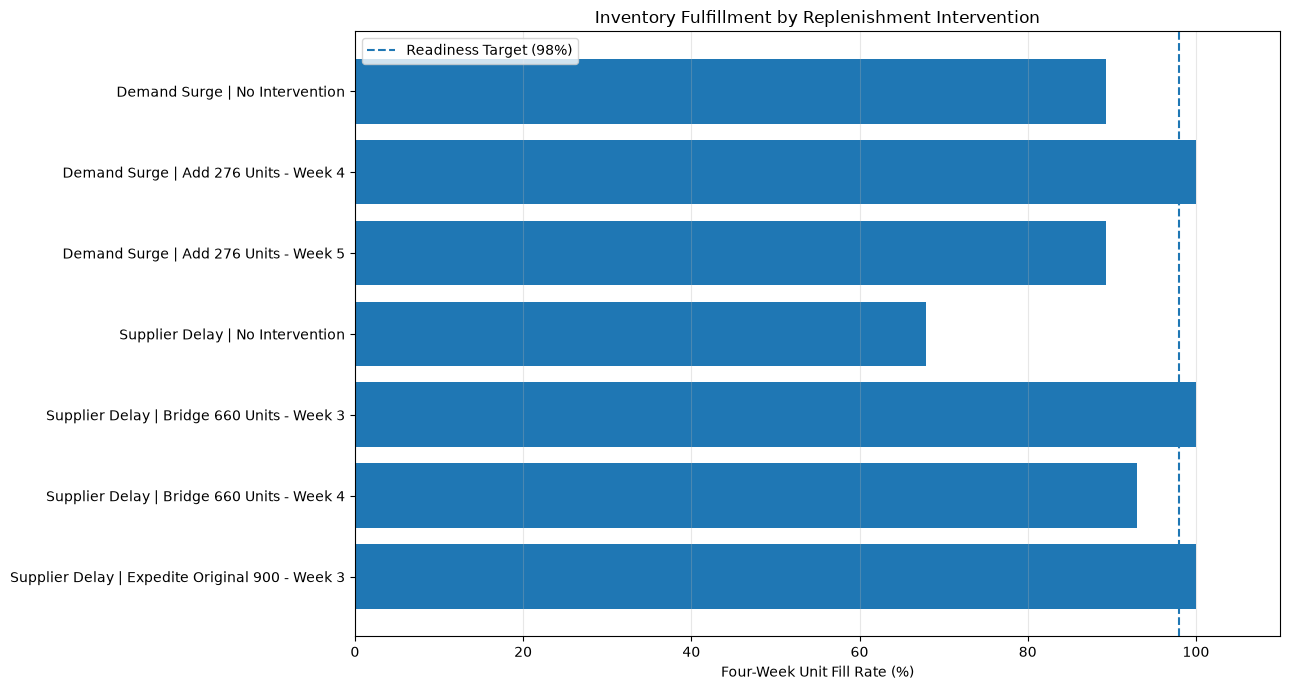

Saved: inventory_fill_rate_by_action.png


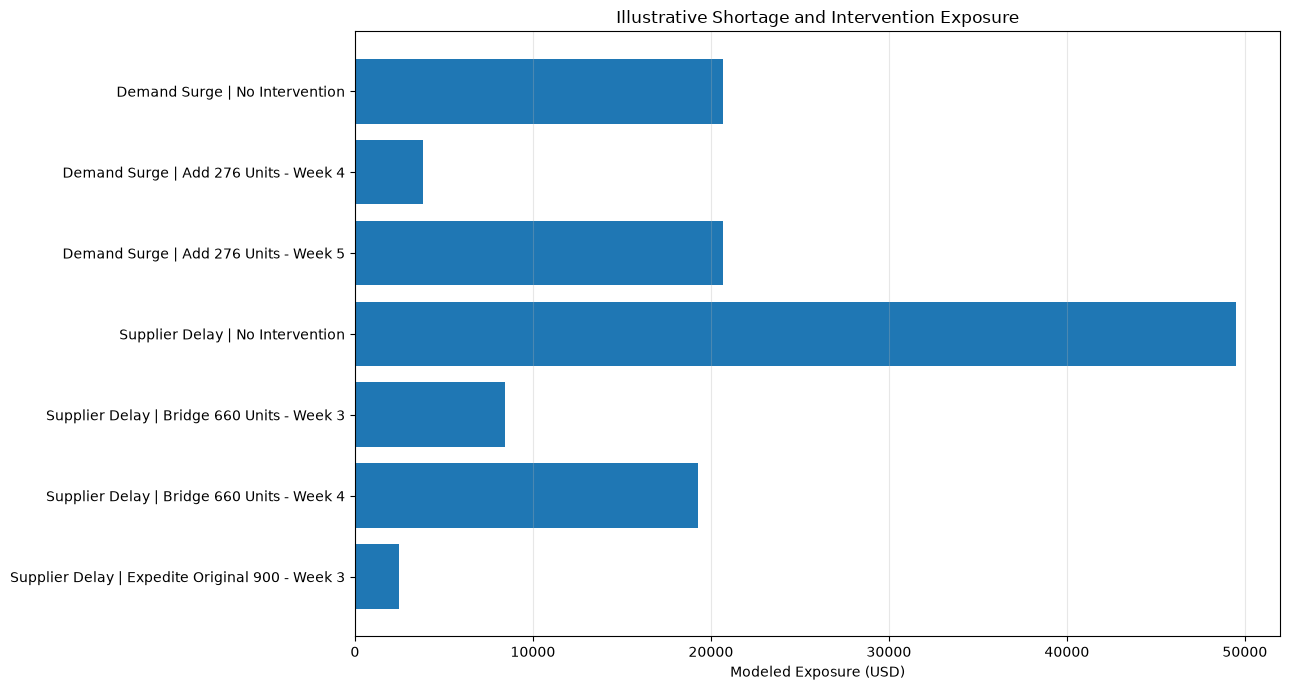

Saved: inventory_modeled_exposure_by_action.png


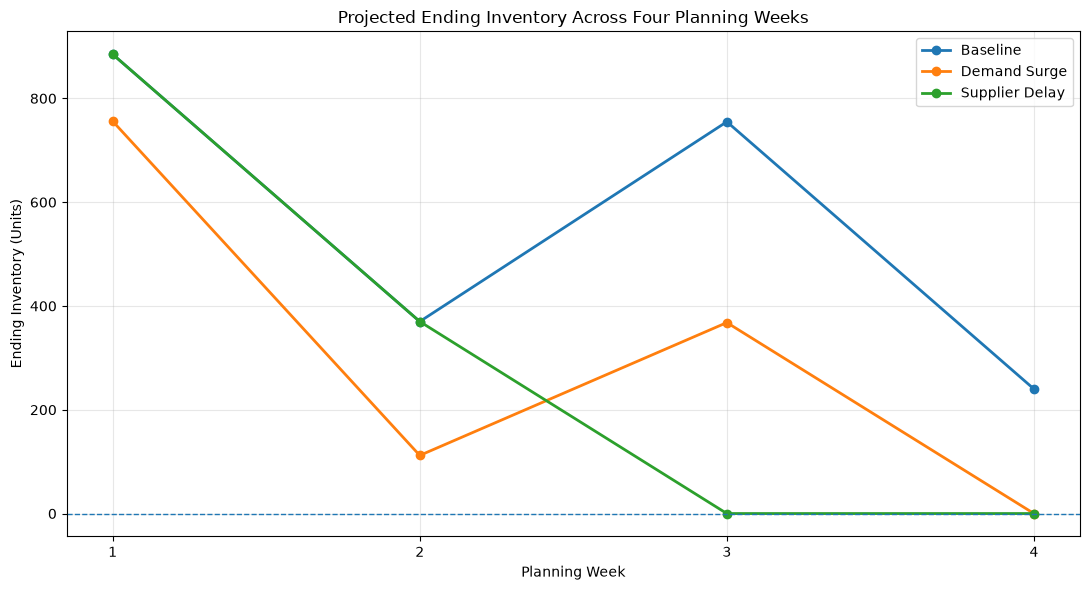

Saved: inventory_ending_balance_by_week.png
Exported: inventory_scenario_definitions.csv (3 rows)
Exported: inventory_weekly_simulation.csv (12 rows)
Exported: inventory_scenario_performance.csv (3 rows)
Exported: inventory_risk_summary.csv (3 rows)
Exported: inventory_intervention_weekly.csv (28 rows)
Exported: inventory_launch_readiness.csv (7 rows)
Exported: inventory_candidate_actions.csv (2 rows)
Exported: inventory_decision_assumptions.csv (6 rows)

===== INVENTORY EXPORT REPORT =====


,File,Rows,Columns,Status
0,inventory_scenario_definitions.csv,3,5,PASS
1,inventory_weekly_simulation.csv,12,12,PASS
2,inventory_scenario_performance.csv,3,8,PASS
3,inventory_risk_summary.csv,3,10,PASS
4,inventory_intervention_weekly.csv,28,10,PASS
5,inventory_launch_readiness.csv,7,32,PASS
6,inventory_candidate_actions.csv,2,32,PASS
7,inventory_decision_assumptions.csv,6,4,PASS



===== FINAL EXPORT VALIDATION =====
CSV files exported: 8
PNG charts exported: 3
Shortage-free interventions: 3
Candidate decisions: 2
All validations: PASS

===== STEP 6 COMPLETE =====


In [6]:
# STEP 6: VISUALIZE AND EXPORT INVENTORY DECISIONS

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# PART 1: DEFINE OUTPUT LOCATIONS
# ------------------------------------------------------------

output_dir = project_root / "data" / "processed"
figures_dir = project_root / "reports" / "figures"

output_dir.mkdir(parents=True, exist_ok=True)
figures_dir.mkdir(parents=True, exist_ok=True)

print("===== OUTPUT DIRECTORIES =====")
print("Data:", output_dir)
print("Figures:", figures_dir)


# ------------------------------------------------------------
# PART 2: VISUALIZE FILL RATE BY INTERVENTION
# ------------------------------------------------------------

chart_data = launch_readiness.copy()

chart_data["Action_Label"] = (
    chart_data["Scenario"]
    + " | "
    + chart_data["Action"]
)

fig, ax = plt.subplots(figsize=(13, 7))

ax.barh(
    chart_data["Action_Label"],
    chart_data["Fill_Rate_Pct"]
)

ax.axvline(
    launch_fill_target_pct,
    linestyle="--",
    label=f"Readiness Target ({launch_fill_target_pct:.0f}%)"
)

ax.set_title(
    "Inventory Fulfillment by Replenishment Intervention"
)

ax.set_xlabel("Four-Week Unit Fill Rate (%)")
ax.set_xlim(0, 110)

ax.invert_yaxis()
ax.grid(axis="x", alpha=0.3)
ax.legend()

fig.tight_layout()

fill_rate_path = (
    figures_dir / "inventory_fill_rate_by_action.png"
)

fig.savefig(
    fill_rate_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("Saved:", fill_rate_path.name)


# ------------------------------------------------------------
# PART 3: VISUALIZE ILLUSTRATIVE ECONOMIC EXPOSURE
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(13, 7))

ax.barh(
    chart_data["Action_Label"],
    chart_data["Illustrative_Exposure_USD"]
)

ax.set_title(
    "Illustrative Shortage and Intervention Exposure"
)

ax.set_xlabel("Modeled Exposure (USD)")

ax.invert_yaxis()
ax.grid(axis="x", alpha=0.3)

fig.tight_layout()

exposure_path = (
    figures_dir / "inventory_modeled_exposure_by_action.png"
)

fig.savefig(
    exposure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("Saved:", exposure_path.name)


# ------------------------------------------------------------
# PART 4: VISUALIZE ENDING INVENTORY ACROSS SCENARIOS
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(11, 6))

for scenario_name, group in (
    inventory_simulation.groupby("Scenario", sort=False)
):

    group = group.sort_values("Week")

    ax.plot(
        group["Week"],
        group["Ending_Inventory"],
        marker="o",
        linewidth=2,
        label=scenario_name
    )

ax.axhline(
    0,
    linestyle="--",
    linewidth=1
)

ax.set_title(
    "Projected Ending Inventory Across Four Planning Weeks"
)

ax.set_xlabel("Planning Week")
ax.set_ylabel("Ending Inventory (Units)")

ax.set_xticks([1, 2, 3, 4])
ax.grid(alpha=0.3)
ax.legend()

fig.tight_layout()

inventory_chart_path = (
    figures_dir / "inventory_ending_balance_by_week.png"
)

fig.savefig(
    inventory_chart_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("Saved:", inventory_chart_path.name)


# ------------------------------------------------------------
# PART 5: DOCUMENT HYPOTHETICAL ECONOMIC ASSUMPTIONS
# ------------------------------------------------------------

decision_assumptions = pd.DataFrame([
    {
        "Parameter": "Launch fill target",
        "Value": launch_fill_target_pct,
        "Unit": "%",
        "Source": "Hypothetical"
    },
    {
        "Parameter": "Watch threshold",
        "Value": watch_fill_threshold_pct,
        "Unit": "%",
        "Source": "Hypothetical"
    },
    {
        "Parameter": "Shortage penalty",
        "Value": shortage_penalty_per_unit,
        "Unit": "USD per unit",
        "Source": "Hypothetical"
    },
    {
        "Parameter": "Emergency supply premium",
        "Value": emergency_premium_per_unit,
        "Unit": "USD per unit",
        "Source": "Hypothetical"
    },
    {
        "Parameter": "Emergency delivery fee",
        "Value": emergency_delivery_fee,
        "Unit": "USD per shipment",
        "Source": "Hypothetical"
    },
    {
        "Parameter": "Original shipment expedite fee",
        "Value": original_expediting_fee,
        "Unit": "USD per shipment",
        "Source": "Hypothetical"
    }
])


# ------------------------------------------------------------
# PART 6: DEFINE DATA EXPORTS
# ------------------------------------------------------------

inventory_exports = {
    "inventory_scenario_definitions.csv":
        scenario_definitions,

    "inventory_weekly_simulation.csv":
        inventory_simulation,

    "inventory_scenario_performance.csv":
        scenario_performance,

    "inventory_risk_summary.csv":
        inventory_risk_summary,

    "inventory_intervention_weekly.csv":
        intervention_weekly,

    "inventory_launch_readiness.csv":
        launch_readiness,

    "inventory_candidate_actions.csv":
        candidate_actions,

    "inventory_decision_assumptions.csv":
        decision_assumptions
}


# ------------------------------------------------------------
# PART 7: EXPORT AND VALIDATE ALL TABLES
# ------------------------------------------------------------

export_records = []

expected_rows = {
    "inventory_scenario_definitions.csv": 3,
    "inventory_weekly_simulation.csv": 12,
    "inventory_scenario_performance.csv": 3,
    "inventory_risk_summary.csv": 3,
    "inventory_intervention_weekly.csv": 28,
    "inventory_launch_readiness.csv": 7,
    "inventory_candidate_actions.csv": 2,
    "inventory_decision_assumptions.csv": 6
}

for filename, dataframe in inventory_exports.items():

    output_path = output_dir / filename

    dataframe.to_csv(
        output_path,
        index=False
    )

    verified = pd.read_csv(output_path)

    assert len(verified) == len(dataframe)

    assert (
        verified.columns.tolist()
        == dataframe.columns.tolist()
    )

    assert len(verified) == expected_rows[filename]

    assert output_path.stat().st_size > 0

    export_records.append({
        "File": filename,
        "Rows": len(verified),
        "Columns": len(verified.columns),
        "Status": "PASS"
    })

    print(f"Exported: {filename} ({len(verified)} rows)")


# ------------------------------------------------------------
# PART 8: VALIDATE FIGURES AND RESULTS
# ------------------------------------------------------------

figure_paths = [
    fill_rate_path,
    exposure_path,
    inventory_chart_path
]

for path in figure_paths:
    assert path.is_file()
    assert path.stat().st_size > 0

inventory_export_report = pd.DataFrame(
    export_records
)

print("\n===== INVENTORY EXPORT REPORT =====")

display(inventory_export_report)

assert len(inventory_export_report) == 8

assert (
    inventory_export_report["Status"] == "PASS"
).all()

assert (
    launch_readiness["Readiness_Status"] == "READY"
).sum() == 3

assert len(candidate_actions) == 2

print("\n===== FINAL EXPORT VALIDATION =====")
print("CSV files exported: 8")
print("PNG charts exported: 3")
print("Shortage-free interventions: 3")
print("Candidate decisions: 2")
print("All validations: PASS")

print("\n===== STEP 6 COMPLETE =====")


In [7]:
# STEP 7A: INTEGRATE INVENTORY RESULTS INTO DUCKDB

from pathlib import Path
import duckdb
import pandas as pd

# ------------------------------------------------------------
# PART 1: CONNECT TO EXISTING DATABASE
# ------------------------------------------------------------

database_path = (
    project_root
    / "data"
    / "warehouse"
    / "demand_intelligence.duckdb"
)

assert database_path.is_file(), "DuckDB database not found."

inventory_con = duckdb.connect(str(database_path))

print("===== INVENTORY DATABASE CONNECTION =====")
print("Connected successfully.")


try:

    # --------------------------------------------------------
    # PART 2: CREATE INVENTORY SCHEMA
    # --------------------------------------------------------

    inventory_con.execute(
        "CREATE SCHEMA IF NOT EXISTS inventory"
    ).fetchall()

    print("\nInventory schema created.")


    # --------------------------------------------------------
    # PART 3: DEFINE INVENTORY DATASETS
    # --------------------------------------------------------

    inventory_specs = {
        "inventory_scenario_definitions.csv": (
            3, "Scenario",
            "Hypothetical inventory and supply inputs",
            "Scenario configuration"
        ),
        "inventory_weekly_simulation.csv": (
            12, "Scenario x Week",
            "Weekly inventory balances and fulfillment",
            "Inventory simulation"
        ),
        "inventory_scenario_performance.csv": (
            3, "Scenario",
            "Demand, shortages and fill rates",
            "Service evaluation"
        ),
        "inventory_risk_summary.csv": (
            3, "Scenario",
            "Shortage timing and magnitude",
            "Inventory risk"
        ),
        "inventory_intervention_weekly.csv": (
            28, "Scenario x Action x Week",
            "Weekly replenishment intervention results",
            "Recovery simulation"
        ),
        "inventory_launch_readiness.csv": (
            7, "Scenario x Action",
            "Readiness and economic tradeoffs",
            "Decision evaluation"
        ),
        "inventory_candidate_actions.csv": (
            2, "Scenario",
            "Lowest modeled exposure among ready actions",
            "Candidate decisions"
        ),
        "inventory_decision_assumptions.csv": (
            6, "Assumption",
            "Hypothetical economic and service parameters",
            "Scenario assumptions"
        )
    }

    load_records = []

    # --------------------------------------------------------
    # PART 4: LOAD EIGHT INVENTORY TABLES
    # --------------------------------------------------------

    for filename, spec in inventory_specs.items():

        expected_rows, grain, meaning, role = spec

        file_path = processed_dir / filename

        assert file_path.is_file(), (
            f"Missing inventory file: {filename}"
        )

        df = pd.read_csv(file_path)

        assert len(df) == expected_rows

        table_name = Path(filename).stem

        assert table_name.isidentifier()

        inventory_con.register(
            "incoming_inventory",
            df
        )

        try:

            inventory_con.execute(
                f"""
                CREATE OR REPLACE TABLE
                    inventory.{table_name}
                AS
                SELECT *
                FROM incoming_inventory
                """
            ).fetchall()

        finally:

            inventory_con.unregister("incoming_inventory")

        # Validate SQL row count.
        sql_rows = inventory_con.execute(
            f"""
            SELECT COUNT(*)
            FROM inventory.{table_name}
            """
        ).fetchall()[0][0]

        assert sql_rows == len(df)

        # ----------------------------------------------------
        # PART 5: UPDATE ARCHITECTURE METADATA
        # ----------------------------------------------------

        inventory_con.execute(
            """
            DELETE FROM metadata.architecture_catalog
            WHERE File_Name = ?
            """,
            [filename]
        ).fetchall()

        inventory_con.execute(
            """
            INSERT INTO metadata.architecture_catalog
            (
                File_Name,
                Source_Module,
                Grain,
                Business_Meaning,
                Analytical_Role
            )
            VALUES (?, ?, ?, ?, ?)
            """,
            [
                filename,
                "Inventory & Launch Readiness",
                grain,
                meaning,
                role
            ]
        ).fetchall()

        # ----------------------------------------------------
        # PART 6: UPDATE DATA QUALITY METADATA
        # ----------------------------------------------------

        missing_cells = int(df.isna().sum().sum())
        duplicate_rows = int(df.duplicated().sum())

        if "Forecast_Week" in df.columns:

            dates = pd.to_datetime(
                df["Forecast_Week"],
                errors="raise"
            )

            start_date = str(dates.min().date())
            end_date = str(dates.max().date())

        else:

            start_date = "N/A"
            end_date = "N/A"

        inventory_con.execute(
            """
            DELETE FROM metadata.data_quality_report
            WHERE File_Name = ?
            """,
            [filename]
        ).fetchall()

        inventory_con.execute(
            """
            INSERT INTO metadata.data_quality_report
            (
                File_Name,
                Source_Module,
                Rows,
                Columns,
                Missing_Cells,
                Duplicate_Rows,
                Start_Date,
                End_Date,
                Row_Check
            )
            VALUES (?, ?, ?, ?, ?, ?, ?, ?, ?)
            """,
            [
                filename,
                "Inventory & Launch Readiness",
                len(df),
                len(df.columns),
                missing_cells,
                duplicate_rows,
                start_date,
                end_date,
                "PASS"
            ]
        ).fetchall()

        load_records.append({
            "Table": f"inventory.{table_name}",
            "CSV_Rows": len(df),
            "SQL_Rows": sql_rows,
            "Status": "PASS"
        })

        print(
            f"Loaded: inventory.{table_name} "
            f"({sql_rows} rows)"
        )


    # --------------------------------------------------------
    # PART 7: CREATE INVENTORY REPORTING VIEWS
    # --------------------------------------------------------

    inventory_views = {

        "v_inventory_weekly": """
            SELECT
                Scenario,
                Week,
                Forecast_Week,
                Beginning_Inventory,
                Inbound_Receipts,
                Demand_Units,
                Fulfilled_Units,
                Shortage_Units,
                Ending_Inventory,
                Weekly_Fill_Rate_Pct
            FROM inventory.inventory_weekly_simulation
        """,

        "v_inventory_scenario_performance": """
            SELECT
                Scenario,
                Total_Demand,
                Total_Fulfilled,
                Total_Shortage,
                Receipts_In_Horizon,
                Shortage_Weeks,
                Ending_Inventory,
                Fill_Rate_Pct
            FROM inventory.inventory_scenario_performance
        """,

        "v_inventory_launch_readiness": """
            SELECT
                Scenario,
                Action,
                Total_Shortage,
                Shortage_Weeks,
                Fill_Rate_Pct,
                Readiness_Status,
                Illustrative_Exposure_USD,
                Exposure_Reduction_vs_No_Action_USD,
                Total_Outstanding_Units
            FROM inventory.inventory_launch_readiness
        """,

        "v_inventory_candidate_actions": """
            SELECT
                Scenario,
                Action,
                Fill_Rate_Pct,
                Illustrative_Exposure_USD,
                Total_Outstanding_Units
            FROM inventory.inventory_candidate_actions
        """
    }

    print("\n===== CREATING INVENTORY REPORTING VIEWS =====")

    for view_name, query in inventory_views.items():

        inventory_con.execute(
            f"""
            CREATE OR REPLACE VIEW reporting.{view_name}
            AS
            {query}
            """
        ).fetchall()

        print("Created:", view_name)


    # --------------------------------------------------------
    # PART 8: VALIDATE INVENTORY VIEW ROW COUNTS
    # --------------------------------------------------------

    expected_view_rows = {
        "v_inventory_weekly": 12,
        "v_inventory_scenario_performance": 3,
        "v_inventory_launch_readiness": 7,
        "v_inventory_candidate_actions": 2
    }

    for view_name, expected in expected_view_rows.items():

        actual = inventory_con.execute(
            f"""
            SELECT COUNT(*)
            FROM reporting.{view_name}
            """
        ).fetchall()[0][0]

        assert actual == expected, (
            f"View row mismatch: {view_name}"
        )

        print(
            f"Validated: {view_name} "
            f"({actual} rows)"
        )


    # --------------------------------------------------------
    # PART 9: VALIDATE COMPLETE DATABASE STRUCTURE
    # --------------------------------------------------------

    schema_rows = inventory_con.execute(
        """
        SELECT
            table_schema,
            COUNT(*) AS Tables
        FROM information_schema.tables
        WHERE table_schema IN (
            'demand',
            'ecommerce',
            'retail',
            'intent',
            'inventory',
            'metadata'
        )
        AND table_type = 'BASE TABLE'
        GROUP BY table_schema
        ORDER BY table_schema
        """
    ).fetchall()

    schema_summary = pd.DataFrame(
        schema_rows,
        columns=["Schema", "Tables"]
    )

    print("\n===== EXPANDED DATABASE STRUCTURE =====")

    display(schema_summary)

    expected_counts = {
        "demand": 8,
        "ecommerce": 4,
        "intent": 2,
        "inventory": 8,
        "metadata": 3,
        "retail": 7
    }

    actual_counts = dict(schema_rows)

    assert actual_counts == expected_counts

    # Validate reporting view total.
    view_count = inventory_con.execute(
        """
        SELECT COUNT(*)
        FROM information_schema.views
        WHERE table_schema = 'reporting'
        """
    ).fetchall()[0][0]

    assert view_count == 11

    # Validate metadata catalog totals.
    metadata_counts = inventory_con.execute(
        """
        SELECT
            (SELECT COUNT(*)
             FROM metadata.architecture_catalog),

            (SELECT COUNT(*)
             FROM metadata.data_quality_report)
        """
    ).fetchall()[0]

    assert metadata_counts == (29, 29)


    # --------------------------------------------------------
    # PART 10: FINAL VALIDATION REPORT
    # --------------------------------------------------------

    inventory_load_report = pd.DataFrame(
        load_records
    )

    print("\n===== INVENTORY TABLE LOAD REPORT =====")

    display(inventory_load_report)

    assert len(inventory_load_report) == 8

    assert (
        inventory_load_report["Status"] == "PASS"
    ).all()

    print("\n===== FINAL DATABASE VALIDATION =====")

    print("Total persistent SQL tables:", 32)
    print("Total reporting views:", view_count)
    print("Architecture catalog entries:", metadata_counts[0])
    print("Data quality catalog entries:", metadata_counts[1])
    print("Eight inventory datasets loaded: PASS")
    print("Four reporting views created: PASS")

    print("\n===== STEP 7A COMPLETE =====")

finally:

    inventory_con.close()

    print("\nDatabase connection closed safely.")


===== INVENTORY DATABASE CONNECTION =====
Connected successfully.

Inventory schema created.
Loaded: inventory.inventory_scenario_definitions (3 rows)
Loaded: inventory.inventory_weekly_simulation (12 rows)
Loaded: inventory.inventory_scenario_performance (3 rows)
Loaded: inventory.inventory_risk_summary (3 rows)
Loaded: inventory.inventory_intervention_weekly (28 rows)
Loaded: inventory.inventory_launch_readiness (7 rows)
Loaded: inventory.inventory_candidate_actions (2 rows)
Loaded: inventory.inventory_decision_assumptions (6 rows)

===== CREATING INVENTORY REPORTING VIEWS =====
Created: v_inventory_weekly
Created: v_inventory_scenario_performance
Created: v_inventory_launch_readiness
Created: v_inventory_candidate_actions
Validated: v_inventory_weekly (12 rows)
Validated: v_inventory_scenario_performance (3 rows)
Validated: v_inventory_launch_readiness (7 rows)
Validated: v_inventory_candidate_actions (2 rows)

===== EXPANDED DATABASE STRUCTURE =====


,Schema,Tables
0,demand,8
1,ecommerce,4
2,intent,2
3,inventory,8
4,metadata,3
5,retail,7



===== INVENTORY TABLE LOAD REPORT =====


,Table,CSV_Rows,SQL_Rows,Status
0,inventory.inventory_scenario_definitions,3,3,PASS
1,inventory.inventory_weekly_simulation,12,12,PASS
2,inventory.inventory_scenario_performance,3,3,PASS
3,inventory.inventory_risk_summary,3,3,PASS
4,inventory.inventory_intervention_weekly,28,28,PASS
5,inventory.inventory_launch_readiness,7,7,PASS
6,inventory.inventory_candidate_actions,2,2,PASS
7,inventory.inventory_decision_assumptions,6,6,PASS



===== FINAL DATABASE VALIDATION =====
Total persistent SQL tables: 32
Total reporting views: 11
Architecture catalog entries: 29
Data quality catalog entries: 29
Eight inventory datasets loaded: PASS
Four reporting views created: PASS

===== STEP 7A COMPLETE =====

Database connection closed safely.



# Inventory & Launch Readiness Simulator — Final Findings

## 1. Research Objective

Develop a scenario-based supply chain planning model
that evaluates inventory availability, replenishment
timing, supplier disruptions, and launch fulfillment.

Connect validated historical demand forecasting outputs
to a hypothetical inventory decision-support system.

## 2. Forecasting Inputs

Source: Multi-Horizon Forecasting Validation

Historical forecast origin: December 29, 2019

Illustrative demand:
- Weekly forecast: 515 units
- Four-week cumulative forecast: 2,060 units

The baseline assumes constant weekly demand and does
not represent observed 2020 sales.

## 3. Inventory Planning Assumptions

Hypothetical supply parameters:

- Starting inventory: 1,400 units
- Original inbound shipment: 900 units
- Normal shipment arrival: Week 3
- Delayed shipment arrival: Week 5
- Demand surge: +25%
- Planning horizon: Four weeks

Shipments arrive at the start of the scheduled week.

Unfulfilled demand is treated as lost sales.

No automatic replenishment is assumed in the
initial scenarios.

## 4. Initial Scenario Results

| Scenario | Demand | Shortage | Fill Rate |
|---|---:|---:|---:|
| Baseline | 2,060 | 0 | 100.00% |
| Demand Surge | 2,576 | 276 | 89.29% |
| Supplier Delay | 2,060 | 660 | 67.96% |

The baseline scenario fulfilled all demand.

The demand-surge scenario produced its first
shortage during Week 4.

The supplier-delay scenario produced its first
shortage during Week 3.

## 5. Replenishment Interventions

Evaluated seven intervention configurations,
including no-action baselines.

Key results:

Demand Surge:
- Adding 276 units in Week 4 eliminated shortages.
- Adding the same units in Week 5 did not prevent
  shortages within the four-week horizon.

Supplier Delay:
- Delivering 660 bridge units in Week 3
  eliminated shortages.
- Delivering 660 bridge units in Week 4 left
  145 units unfulfilled.
- Expediting the original 900-unit shipment
  to Week 3 eliminated shortages.

Shipment timing was critical to fulfillment.

## 6. Launch-Readiness Decision Criteria

Hypothetical fulfillment target: 98%

A READY status required:
- Meeting the fill-rate target
- Zero shortage weeks

WATCH and AT RISK statuses indicated lower
modeled inventory-fulfillment performance.

These categories do not certify actual engineering,
manufacturing, quality, or product launch readiness.

## 7. Illustrative Economic Assumptions

- Unfulfilled-demand penalty: $75 per unit
- Emergency supply premium: $12 per unit
- Emergency delivery fee: $500
- Original shipment expediting fee: $2,500

The financial model excludes full purchase costs,
holding costs, and post-horizon consequences.

All economic parameters are hypothetical.

## 8. Candidate Recovery Decisions

Demand Surge:
- Candidate: Add 276 units in Week 4
- Modeled fill rate: 100%
- Illustrative exposure: $3,812
- Modeled exposure reduction: $16,888

Supplier Delay:
- Candidate: Expedite original 900 units to Week 3
- Modeled fill rate: 100%
- Illustrative exposure: $2,500
- Modeled exposure reduction: $47,000

These reductions are relative to no-action scenarios
under assumed costs.

They are not demonstrated business savings.

The supplier-delay bridge alternatives retain the
original 900-unit shipment scheduled for Week 5.

Future inventory obligations must be considered
before implementing an additional purchase decision.

## 9. Technical Architecture

Developed:
- Four-week inventory-flow simulation
- Three initial inventory scenarios
- Seven replenishment alternatives
- Shortage and service-level risk metrics
- Illustrative economic decision analysis

Exported:
- Eight validated inventory CSV datasets
- Three PNG figures

Integrated into DuckDB:
- Eight inventory analytical tables
- Four inventory reporting views

Expanded database:
- 32 persistent tables
- 11 reporting views
- 29 architecture metadata entries
- 29 data-quality metadata entries

All new data table row counts reconciled.

## 10. Business Implications

The simulation demonstrates how:
- Demand surges can exhaust planned inventory
- Supplier delays can create shortages even when
  total planned supply is sufficient
- Replenishment timing affects lost-sales exposure
- Inventory recovery actions can be compared
  against operational service-level objectives
- Supply obligations beyond the planning horizon
  can affect future inventory decisions

## 11. Limitations

- Inventory and supplier parameters are hypothetical.
- The forecast originates from 2019 historical data.
- The simulator covers only one product demand series.
- Demand uncertainty is not yet propagated across
  multiple inventory simulation trials.
- No supplier feasibility or capacity constraints
  have been independently verified.
- Financial assumptions are illustrative.
- No real operational savings have been measured.
- Post-horizon inventory economics remain incomplete.
- Current database construction spans multiple
  notebooks and requires pipeline consolidation.

## 12. Next Development Phase

1. Conduct inventory sensitivity analysis
2. Evaluate demand and supplier lead-time uncertainty
3. Consolidate the DuckDB rebuild pipeline
4. Assess external demand-signal integration
5. Develop Power BI executive dashboards
6. Validate forecasting-to-inventory data flows
7. Prepare the final GitHub and website case study
`m`